# 01 — Problem, data and exploratory analysis

## Problem: detecting rooftop solar from grid-import data (Sri Lanka)

After the 2022 electricity crisis and the tariff increases that followed, thousands of Sri Lankan households
installed rooftop solar. Distribution utilities (CEB, LECO) need to know **which households have solar** to plan
feeders, manage reverse power flow and update records, including systems that were never registered.

**Task.** Given one day of a household's *grid import* (kWh per hour, from a smart meter), predict whether a
rooftop solar system is installed. A household is flagged by averaging its day-level predictions.

**Data.** LIRNEasia — *Residential Electricity Consumption Dataset for Sri Lanka (RECON-SL)*: 15-minute smart-meter
readings from LECO customers (Moratuwa area), October 2023 – December 2024, released for research.
Source: https://www.kaggle.com/datasets/lirneasia/sri-lankan-residential-electricity-consumption

**Label (fixed before modelling).** The meter's *export register* records energy sent back to the grid.
* A household has solar if it exported more than **1 kWh** during the period.
* A day is labelled **solar installed** from the first day the household exported more than **0.1 kWh**
  (some households install part-way through).
* Export readings define the label only — they are **never** used as features.

In [1]:
import sys, zipfile
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
from src.features import HOURS, make_features
sns.set_theme(style='whitegrid', context='notebook')
FIG = '../reports/figures/'
import os; os.makedirs(FIG, exist_ok=True)
hd = pd.read_parquet('../data/processed/household_days.parquet')
hd.head()

,hh,day,h00,h01,h02,h03,h04,h05,h06,h07,...,h22,h23,export_kwh_day,export_kwh,export_steps,has_solar,first_export_day,solar_installed,unit,month
0,ID0052,2023-10-30,0.230957,0.199951,0.197998,0.172119,0.157959,0.224854,0.175049,0.083984,...,0.291992,0.447021,0.0,0.0,15815,0,NaT,0,ID0052:0,10
1,ID0052,2023-10-31,0.212891,0.241943,0.194092,0.201904,0.204102,0.182861,0.175049,0.097168,...,0.221924,0.235107,0.0,0.0,15815,0,NaT,0,ID0052:0,10
2,ID0052,2023-11-01,0.203857,0.227051,0.219971,0.205078,0.230957,0.209229,0.230713,0.098145,...,0.272705,0.271973,0.0,0.0,15815,0,NaT,0,ID0052:0,11
3,ID0052,2023-11-02,0.246094,0.242920,0.223145,0.208984,0.227051,0.179932,0.316895,0.107178,...,0.296875,0.253174,0.0,0.0,15815,0,NaT,0,ID0052:0,11
4,ID0052,2023-11-03,0.220947,0.220947,0.224121,0.203857,0.224121,0.317871,0.245117,0.094971,...,0.257080,0.228760,0.0,0.0,15815,0,NaT,0,ID0052:0,11


## 1. Size and structure

In [2]:
hh = hd.groupby('hh').agg(has_solar=('has_solar','first'), days=('day','size'),
                         first_export=('first_export_day','first'), first_day=('day','min'))
summary = pd.Series({
    'household-days': len(hd),
    'households': len(hh),
    'households with solar': int(hh.has_solar.sum()),
    'share of households with solar': f"{hh.has_solar.mean():.1%}",
    'solar-installed days': f"{hd.solar_installed.mean():.1%}",
    'evaluation units (household-periods)': hd.unit.nunique(),
    'date range': f"{hd.day.min().date()} to {hd.day.max().date()}",
    'median days per household': int(hh.days.median()),
})
summary.to_frame('value')

,value
household-days,452811
households,2925
households with solar,492
share of households with solar,16.8%
solar-installed days,14.6%
evaluation units (household-periods),2990
date range,2023-10-01 to 2024-12-22
median days per household,159


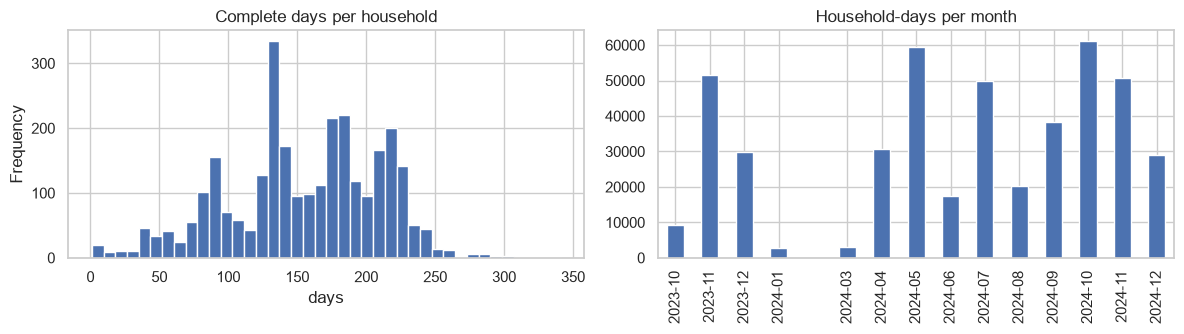

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
hh.days.plot.hist(bins=40, ax=ax[0], color='#4C72B0'); ax[0].set(title='Complete days per household', xlabel='days')
hd.groupby(hd.day.dt.to_period('M')).size().plot.bar(ax=ax[1], color='#4C72B0')
ax[1].set(title='Household-days per month', xlabel='')
plt.tight_layout(); plt.savefig(FIG+'eda_coverage.png', dpi=120); plt.show()

Coverage grows over time because more smart meters report in later months. Only *near-complete* days
(≥ 90 of 96 fifteen-minute readings) are kept, so every row has a full 24-hour profile.

## 2. The signal: average hourly import

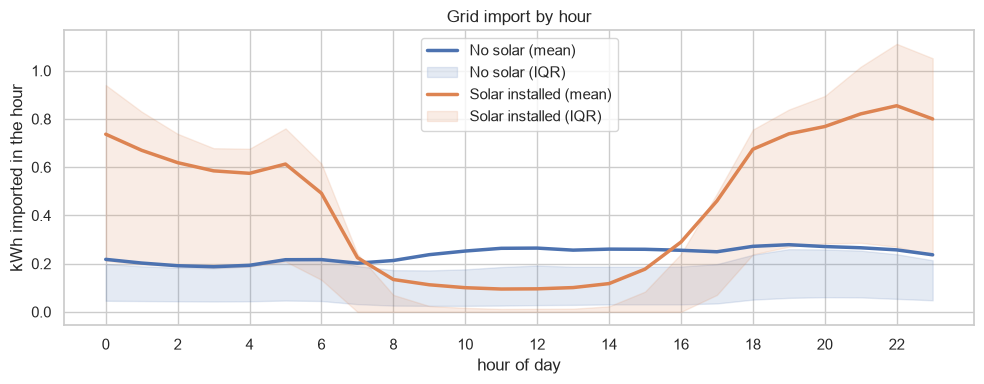

In [4]:
prof = hd.groupby('solar_installed')[HOURS].agg(['mean'])
q = {k: hd[hd.solar_installed==k][HOURS] for k in (0, 1)}
fig, ax = plt.subplots(figsize=(10, 4))
for k, c, lab in [(0, '#4C72B0', 'No solar'), (1, '#DD8452', 'Solar installed')]:
    ax.plot(range(24), q[k].mean().values, color=c, lw=2.5, label=f'{lab} (mean)')
    ax.fill_between(range(24), q[k].quantile(.25).values, q[k].quantile(.75).values, color=c, alpha=.15, label=f'{lab} (IQR)')
ax.set(xticks=range(0, 24, 2), xlabel='hour of day', ylabel='kWh imported in the hour', title='Grid import by hour')
ax.legend(); plt.tight_layout(); plt.savefig(FIG+'eda_hourly_profile.png', dpi=120); plt.show()

Solar households draw almost nothing from the grid between about 09:00 and 15:00 — the panels cover the
load — and then import heavily in the evening. Non-solar households have a flat daytime profile. This "solar bowl"
is the physical signal the models learn. Solar households also use more electricity overall (larger homes, more
appliances), so total consumption alone carries some signal too.

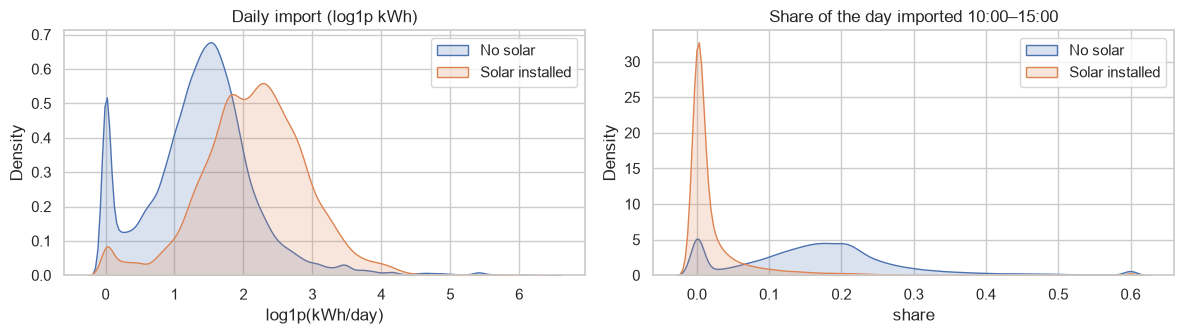

days with (almost) zero import: {0: 0.0762, 1: 0.0155}


In [5]:
tot = hd[HOURS].sum(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for k, c, lab in [(0, '#4C72B0', 'No solar'), (1, '#DD8452', 'Solar installed')]:
    sns.kdeplot(np.log1p(tot[hd.solar_installed==k]), ax=ax[0], color=c, label=lab, fill=True, alpha=.2)
ax[0].set(title='Daily import (log1p kWh)', xlabel='log1p(kWh/day)'); ax[0].legend()
midshare = hd[['h10','h11','h12','h13','h14']].sum(axis=1) / tot.clip(lower=1e-3)
for k, c, lab in [(0, '#4C72B0', 'No solar'), (1, '#DD8452', 'Solar installed')]:
    sns.kdeplot(midshare[hd.solar_installed==k].clip(0, .6), ax=ax[1], color=c, label=lab, fill=True, alpha=.2)
ax[1].set(title='Share of the day imported 10:00–15:00', xlabel='share'); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG+'eda_distributions.png', dpi=120); plt.show()
print('days with (almost) zero import:', (tot < 0.05).groupby(hd.solar_installed).mean().round(4).to_dict())

Some non-solar days have near-zero import (vacant houses, travel). These are a natural source of confusion:
a solar home on a sunny day and an empty home both import little at midday — the evening and night profile
separates them.

## 3. Individual households

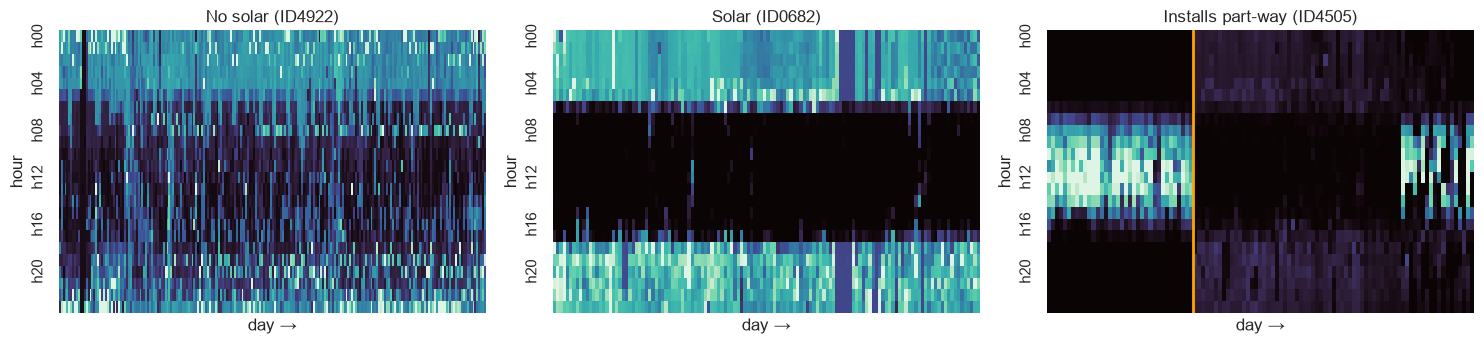

In [6]:
def heat(h, ax, title):
    d = hd[hd.hh == h].set_index('day')[HOURS]
    sns.heatmap(d.T, ax=ax, cmap='mako', cbar=False, xticklabels=False, yticklabels=4, vmin=0, vmax=np.nanpercentile(d, 98))
    fe = hh.loc[h, 'first_export']
    if pd.notna(fe) and fe > d.index.min():
        ax.axvline(d.index.get_loc(fe), color='orange', lw=2)
    ax.set(title=title, xlabel='day →', ylabel='hour')
rng = np.random.default_rng(3)
non = rng.choice(hh[hh.has_solar==0].index); sol = rng.choice(hh[(hh.has_solar==1) & (hh.first_export==hh.first_day)].index)
ms = hd.assign(ms=hd[['h10','h11','h12','h13']].sum(axis=1) / hd[HOURS].sum(axis=1).clip(lower=1e-3))
cand = hh[(hh.has_solar==1) & ((hh.first_export - hh.first_day).dt.days > 60)].index
chg = ms[ms.hh.isin(cand)].groupby(['hh','solar_installed']).ms.agg(['mean','size']).unstack()
chg = chg[(chg[('size',0)] >= 30) & (chg[('size',1)] >= 30)]
late = (chg[('mean',0)] - chg[('mean',1)]).idxmax()  # clearest before/after change
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
heat(non, ax[0], f'No solar ({non})'); heat(sol, ax[1], f'Solar ({sol})'); heat(late, ax[2], f'Installs part-way ({late})')
plt.tight_layout(); plt.savefig(FIG+'eda_heatmaps.png', dpi=120); plt.show()

Each column is a day, each row an hour (darker = less import). The solar household shows a dark daytime band;
the right-hand household shows the band appearing after installation (orange line = first export). This is why
days before the first export are labelled *no solar*.

55 households start exporting more than 14 days after their data begins


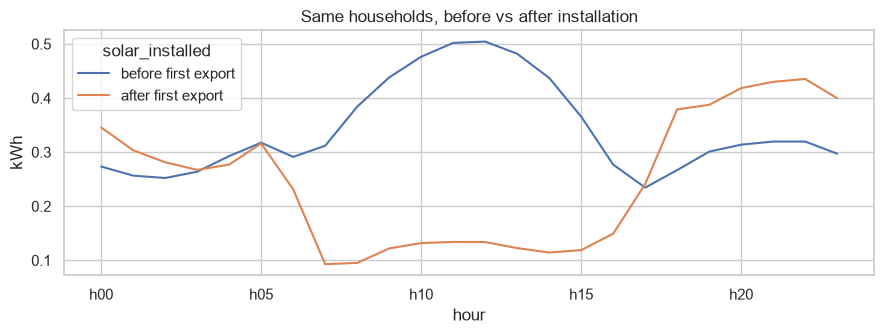

In [7]:
late_hh = hh[(hh.has_solar==1) & ((hh.first_export - hh.first_day).dt.days > 14)].index
print(f'{len(late_hh)} households start exporting more than 14 days after their data begins')
lt = hd[hd.hh.isin(late_hh)]
ax = lt.groupby('solar_installed')[HOURS].mean().T.rename(columns={0:'before first export', 1:'after first export'}).plot(figsize=(9,3.5))
ax.set(title='Same households, before vs after installation', xlabel='hour', ylabel='kWh'); plt.tight_layout()
plt.savefig(FIG+'eda_before_after.png', dpi=120); plt.show()

## 4. Does the meter label agree with what households said in the survey?

In [8]:
with zipfile.ZipFile('../data/raw/recon_sl.zip') as zf:
    sv = pd.read_csv(zf.open('data/data/survey_data/wave_1/w1_electricity_generation_water_heating_cooking.csv'))
sv = sv.set_index('household_ID')['generate_electicity_using_solar_energy']
j = hh.join(sv, how='inner')
ct = pd.crosstab(j.has_solar.map({0:'meter: no export', 1:'meter: exports'}), j.generate_electicity_using_solar_energy, margins=True)
print(f'{len(j)} smart-meter households also answered the wave-1 survey'); ct

1424 smart-meter households also answered the wave-1 survey


generate_electicity_using_solar_energy,No,Yes,All
has_solar,,,
meter: exports,29,171,200
meter: no export,1191,33,1224
All,1220,204,1424


The survey (wave 1, early in the period) and the meter mostly agree. Disagreements are expected: some
households installed solar after the survey, some solar systems are off-grid (no export), and survey answers have
errors. **The meter's export register is a physical measurement, so it is the label; the survey is not used.**

## 5. Leakage checks

| Possible leak | Why it leaks | Action |
|---|---|---|
| `exportkwh`, `avgexportkw`, `exportkvarh` | Directly measure exported solar energy (the label) | **Excluded** — never read into features |
| `EXPORT` flag / meter sub-type (6-hour files) | Meter configured for net metering ⇒ solar | Not used (only 15-minute import data is read) |
| Power factor, reactive power | Inverters change them; partly reflect export | Excluded |
| Same household in train and test | Days of one home are near-duplicates | **Grouped splits**: a household is entirely in train or test |
| Threshold / hyperparameters chosen on test | Optimistic score | Chosen on training households only |
| Calendar month | Share of solar days per month swings 7%–53% because of *which meters reported*, not sunlight. A first model ranked `month` #2 by SHAP | **Excluded** — the model sees only the consumption shape |

A further check: no single feature should perfectly predict the label (that would suggest a hidden leak).

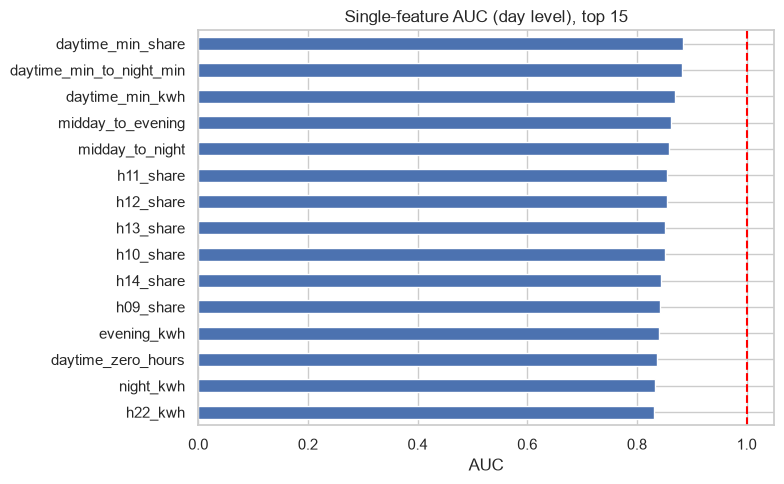

daytime_min_share           0.8848
daytime_min_to_night_min    0.8815
daytime_min_kwh             0.8695
midday_to_evening           0.8619
midday_to_night             0.8583
dtype: float64

In [9]:
X = make_features(hd[HOURS])
y = hd['solar_installed'].values
auc = {c: roc_auc_score(y, X[c].fillna(0)) for c in X.columns}
auc = pd.Series({c: max(v, 1 - v) for c, v in auc.items()}).sort_values(ascending=False)
ax = auc.head(15).sort_values().plot.barh(figsize=(8, 5), color='#4C72B0')
ax.set(title='Single-feature AUC (day level), top 15', xlabel='AUC'); ax.axvline(1.0, color='red', ls='--')
plt.tight_layout(); plt.savefig(FIG+'eda_single_feature_auc.png', dpi=120); plt.show()
auc.head(5).round(4)

The best single feature reaches a day-level AUC well below 1.0 — strong but not perfect, as expected from a real
physical signal (cloudy days, vacant houses and high daytime loads blur it). Combining features is what the
models add.

## 6. Preprocessing summary

1. **Cumulative → interval energy.** Meter registers are cumulative; 15-minute energy = difference between
   consecutive readings of the same household.
2. **Cleaning.** Steps are kept only when readings are exactly 15 minutes apart and the difference is between
   0 and 10 kWh (negative jumps and spikes are meter resets/glitches).
3. **Day profiles.** Steps are summed to 24 hourly values per household-day; days with fewer than 90/96 clean
   steps are dropped, so there are **no missing values** in the modelling table (no imputation needed).
4. **Features** (`src/features.py`): hourly kWh, each hour's share of the day (scale-free shape), midday / night /
   evening ratios, daytime minimum, "bowl depth", peak and trough hour. Calendar month is deliberately excluded (see section 5). Shares and ratios remove the effect of
   household size, which is why tree models need no scaling; scaling is applied inside the pipeline for the
   distance- and gradient-based models (logistic regression, KNN).
5. **Class imbalance.** ~15% of days are solar. Metrics include F1, precision, recall and AUC, not only accuracy,
   and the baseline (always "no solar") is reported.